# A19 每个人选择最快通道，为什么整体变慢？

把30位参与者看成具有有限信息的个体。每人根据上一轮的通道时间改选路线，观察反馈、震荡与统一分流。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 写清容量反馈
两个通道耗时随人数增长，参数是教学假设。每个人只能看到上一轮耗时；如果所有人同时改选，就可能集体挤向另一条路。

In [2]:
import numpy as np
import pandas as pd

def travel_times(counts):
    return np.array([4.0 + 0.45 * counts[0], 9.0 + 0.1 * counts[1]])
assert np.allclose(travel_times([0, 0]), [4, 9])
population = 30

### 2. 比较全部参与与部分参与的同步更新
所有参与者根据上一轮的旧状态作决定；switch_probability控制本轮有多少人参与更新。这仍是同步更新。真正的异步更新需要逐人修改状态，让后面的人看到新的拥堵，本例没有实现那种机制。

In [3]:
def simulate_routes(seed, rounds=40, switch_probability=1.0):
    rng = np.random.default_rng(seed)
    routes = rng.integers(0, 2, population)
    history = []
    for t in range(rounds):
        counts = np.bincount(routes, minlength=2)
        times = travel_times(counts)
        history.append({'round': t, 'route_a': int(counts[0]), 'route_b': int(counts[1]), 'mean_minutes': float(np.dot(counts, times) / population)})
        best = int(times.argmin())
        switch = rng.random(population) < switch_probability
        routes = np.where(switch, best, routes)
    return pd.DataFrame(history)
all_switch = simulate_routes(19)
partial_switch = simulate_routes(19, switch_probability=0.15)
assert (all_switch.route_a + all_switch.route_b == population).all()

### 3. 统一分配的目标是什么
枚举所有人数分配，最小化总耗时。系统总量更优不代表每个人都愿意接受，个体是否想改路将在博弈课单独讨论。

In [4]:
splits = np.arange(population + 1)
total_times = np.array([np.dot([a, population - a], travel_times([a, population - a])) for a in splits])
best_a = int(splits[total_times.argmin()])
coordinated = float(total_times.min() / population)
all_switch.to_csv(OUT_DIR / 'synchronous.csv', index=False)
partial_switch.to_csv(OUT_DIR / 'partial.csv', index=False)
plt.plot(all_switch['round'], all_switch.mean_minutes, label='全部同时更新')
plt.plot(partial_switch['round'], partial_switch.mean_minutes, label='15%概率更新')
plt.axhline(coordinated, linestyle='--', label='统一分流')
plt.xlabel('反馈轮次')
plt.ylabel('平均通行分钟')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'feedback.png')
plt.close()

### 4. 报告对行为假设的敏感性
先给出这个种子的轨迹，再重复种子；不要把单条漂亮曲线当作普遍规律。

In [5]:
means = [float(simulate_routes(s, switch_probability=0.15).mean_minutes.iloc[-10:].mean()) for s in range(20)]
metrics = {'coordinated_route_a': best_a, 'coordinated_mean': coordinated, 'synchronous_last10': float(all_switch.mean_minutes.iloc[-10:].mean()), 'partial_last10_mean_across_runs': float(np.mean(means)), 'partial_run_std': float(np.std(means, ddof=1))}
recommendation = f'系统总耗时最小的人数分配是A通道{best_a}人、B通道{population - best_a}人，平均{coordinated:.2f}分钟。自主更新的表现依赖更新频率；实施分流前需要验证参与者是否遵守与通道容量模型是否合理。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'coordinated_route_a': 10, 'coordinated_mean': 10.166666666666666, 'synchronous_last10': 14.75, 'partial_last10_mean_across_runs': 10.591725, 'partial_run_std': 0.10670082066965998}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

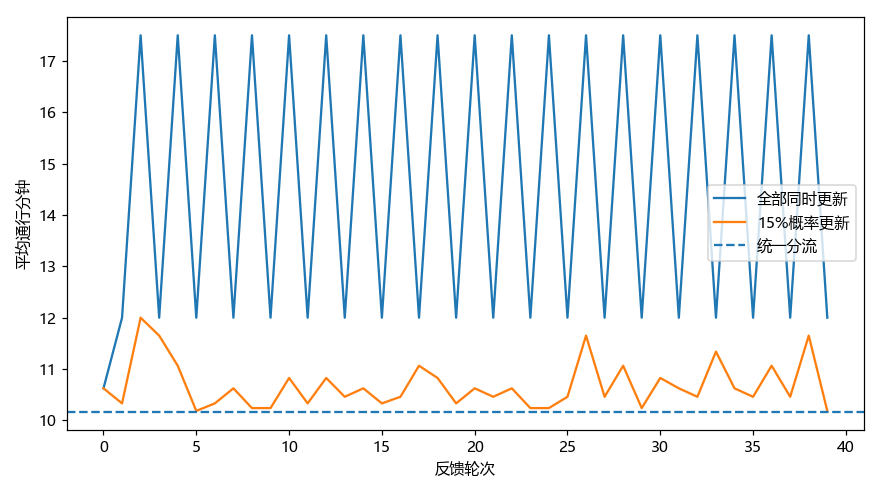

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
这是原创NumPy个体仿真，未依赖Mesa。行为参数未经现实校准；不能把同步更新导致的震荡误写成任何现实人群必然的行为。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。